In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("global_food_delivery_enriched_market_2026.csv")
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 26 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             8000 non-null   str    
 1   metro_city                           8000 non-null   str    
 2   cuisine_category                     8000 non-null   str    
 3   order_channel                        8000 non-null   str    
 4   order_value_usd                      8000 non-null   float64
 5   discount_applied_usd                 8000 non-null   float64
 6   delivery_distance_km                 8000 non-null   float64
 7   estimated_prep_time_min              8000 non-null   int64  
 8   actual_delivery_time_min             8000 non-null   float64
 9   delivery_fee_usd                     8000 non-null   float64
 10  customer_rating                      8000 non-null   float64
 11  restaurant_price_tier                8000

In [3]:
df.describe()
print(df.describe())

       order_value_usd  discount_applied_usd  delivery_distance_km  \
count      8000.000000           8000.000000           8000.000000   
mean         30.222839              3.328607              3.048638   
std          26.366910              5.183003              3.937749   
min           3.500000              0.000000              0.000000   
25%          12.920000              0.000000              0.000000   
50%          21.705000              1.530000              1.600000   
75%          37.892500              4.440000              4.500000   
max         145.000000             35.000000             22.000000   

       estimated_prep_time_min  actual_delivery_time_min  delivery_fee_usd  \
count               8000.00000               8000.000000       8000.000000   
mean                  18.04200                 11.272588          2.962597   
std                    6.76934                 13.533084          2.672989   
min                    5.00000                  0.000000 

In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["order_channel"].value_counts())
print(df.groupby("order_channel")["delivery_distance_km"].mean())

Missing values: 0
Duplicate rows: 0
order_channel
Online Delivery App    5255
Dine-In POS            1577
Takeaway / Pickup      1168
Name: count, dtype: int64
order_channel
Dine-In POS            0.000000
Online Delivery App    4.641123
Takeaway / Pickup      0.000000
Name: delivery_distance_km, dtype: float64


In [5]:
calc = (df["order_value_usd"] - df["discount_applied_usd"] + df["delivery_fee_usd"]).round(2)
print("Rows that don't match:", (calc != df["net_effective_order_price"]).sum())

Rows that don't match: 0


In [6]:
delivery = df[df["order_channel"] == "Online Delivery App"].copy()
print(len(delivery))

5255


In [7]:
#1 does peak hour slow things down
peak = delivery.groupby("is_peak_hour")[
    ["estimated_prep_time_min", "actual_delivery_time_min",
     "total_fulfillment_time_min", "customer_rating"]
].mean().round(2)
peak

,estimated_prep_time_min,actual_delivery_time_min,total_fulfillment_time_min,customer_rating
is_peak_hour,,,,
False,15.89,14.87,30.76,4.30
True,23.54,20.49,44.03,4.12


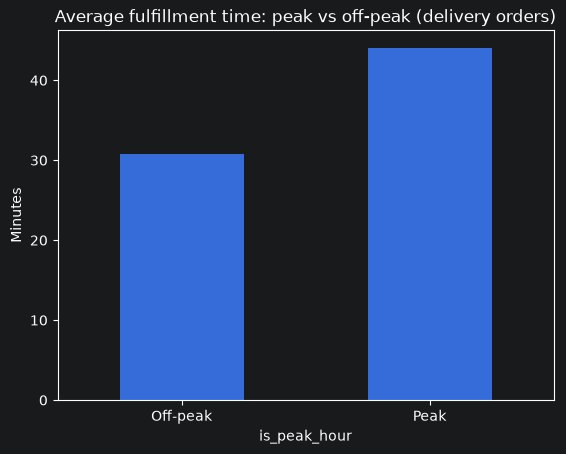

In [8]:
peak["total_fulfillment_time_min"].plot(kind="bar")
plt.title("Average fulfillment time: peak vs off-peak (delivery orders)")
plt.xticks([0, 1], ["Off-peak", "Peak"], rotation=0)
plt.ylabel("Minutes")
plt.savefig("peak_vs_offpeak.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
#how much does weather slow down deliveries
weather = delivery.groupby("weather_condition").agg(
    orders=("order_id", "count"),
    avg_time=("total_fulfillment_time_min", "mean"),
    avg_rating=("customer_rating", "mean")
).round(2).sort_values("avg_time")
weather

,orders,avg_time,avg_rating
weather_condition,,,
Cloudy / Fog,795,34.46,4.28
Clear,2870,34.97,4.27
Rainy,1159,37.66,4.24
Heavy Rain / Storm,431,43.30,3.86


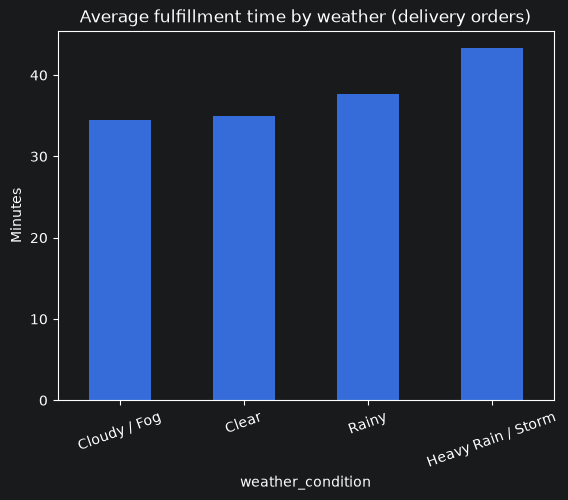

In [10]:
weather["avg_time"].plot(kind="bar")
plt.title("Average fulfillment time by weather (delivery orders)")
plt.ylabel("Minutes")
plt.xticks(rotation=20)
plt.savefig("weather_vs_time.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
#3 do cities and cuisines differ?
city = delivery.groupby("metro_city").agg(
    orders=("order_id", "count"),
    avg_time=("total_fulfillment_time_min", "mean"),
    avg_rating=("customer_rating", "mean"),
    avg_margin=("estimated_restaurant_net_margin_usd", "mean")
).round(2).sort_values("avg_time")
city

,orders,avg_time,avg_rating,avg_margin
metro_city,,,,
Seoul,320,34.68,4.21,9.90
Sydney,360,35.22,4.24,9.95
Paris,405,35.56,4.25,9.70
Toronto,298,35.70,4.23,9.81
Tokyo,583,35.85,4.31,9.57
Berlin,394,36.16,4.20,9.08
Mumbai,313,36.25,4.23,10.31
Jakarta,531,36.28,4.25,9.11
New York,691,36.62,4.20,9.38


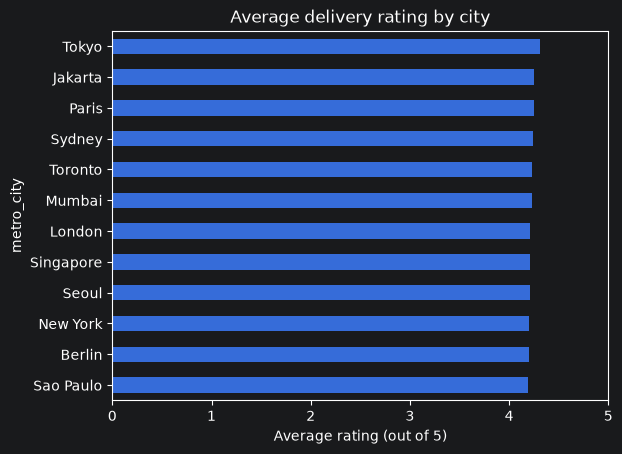

In [12]:
city["avg_rating"].sort_values().plot(kind="barh")
plt.xlim(0, 5)
plt.title("Average delivery rating by city")
plt.xlabel("Average rating (out of 5)")
plt.savefig("rating_by_city.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
cuisine = delivery.groupby("cuisine_category").agg(
    orders=("order_id", "count"),
    avg_time=("total_fulfillment_time_min", "mean"),
    avg_rating=("customer_rating", "mean"),
    avg_margin=("estimated_restaurant_net_margin_usd", "mean")
).round(2).sort_values("avg_margin")
cuisine

,orders,avg_time,avg_rating,avg_margin
cuisine_category,,,,
Mexican & Tacos,437,36.77,4.23,9.20
Italian & Pizza,824,35.77,4.25,9.24
Burgers & Fast Food,1177,35.59,4.25,9.26
Healthy & Bowls,567,35.82,4.24,9.53
Indonesian & Asian Street Food,793,36.80,4.22,9.55
Indian & Curries,512,36.08,4.19,10.09
Japanese & Sushi,945,36.67,4.21,10.18


In [14]:
#4 which orders lose money
losing = delivery[delivery["estimated_restaurant_net_margin_usd"] < 0]
print(len(losing), round(len(losing) / len(delivery) * 100, 1))

91 1.7


In [15]:
delivery["value_band"] = pd.cut(
    delivery["order_value_usd"],
    bins=[0, 5, 8, 12, 20, 200],
    labels=["$0-5", "$5-8", "$8-12", "$12-20", "$20+"]
)

bands = delivery.groupby("value_band", observed=True).agg(
    orders=("order_id", "count"),
    avg_margin=("estimated_restaurant_net_margin_usd", "mean"),
    losing_orders=("estimated_restaurant_net_margin_usd", lambda s: (s < 0).sum())
).round(2)
bands

,orders,avg_margin,losing_orders
value_band,,,
$0-5,175,-0.00,91
$5-8,341,0.93,0
$8-12,650,2.19,0
$12-20,1273,4.32,0
$20+,2816,15.29,0


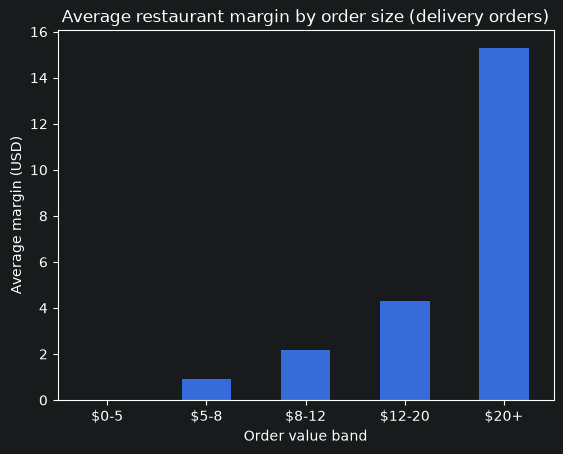

In [16]:
bands["avg_margin"].plot(kind="bar")
plt.title("Average restaurant margin by order size (delivery orders)")
plt.xlabel("Order value band")
plt.ylabel("Average margin (USD)")
plt.xticks(rotation=0)
plt.savefig("margin_by_order_size.png", dpi=150, bbox_inches="tight")
plt.show()

Conclusions and Recommendations

All delivery-time and rating findings use delivery orders only (5,255 of 8,000 orders), because dine-in and takeaway rows have no delivery distance or time.

Key findings
Peak hours slow deliveries sharply. Peak-hour delivery orders took about 44 minutes vs 31 off-peak (about 43% longer) and were rated lower (4.12 vs 4.30). Both kitchen prep time (about 24 vs 16 min) and courier time (about 20 vs 15 min) rise at peak.
Storms add delay on top of peak hour. Heavy rain or storms averaged about 43 minutes vs about 35 in clear weather, and ratings fell from 4.27 to 3.86. A storm during peak hour was the worst case at about 55 minutes.
Ratings hold steady until about 40 minutes, then fall. Ratings were about 4.35 up to 40 minutes, 4.18 between 40 and 60, and only 3.19 above 60 minutes (421 orders, about 8% of deliveries).
Discounts and order size don't affect ratings. Their correlation with rating is about 0. Delivery time (-0.43), delivery fee (-0.38) and distance (-0.34) are all associated with lower ratings, but they move together, so no single cause can be claimed.
Delivery earns the restaurant less per order. Delivery orders are the same size (about $30) and get similar discounts (about 12%), yet restaurants keep about $9.57 per order vs $13.94 for dine-in, which is 32% of sales vs 46%. The pattern holds in all three price tiers. Delivery still produces the most total margin because it has the most orders.
Tiny orders lose money. All 91 money-losing orders are delivery orders under about $4.10 (average $3.60), mostly from budget restaurants, and their average delivery fee ($4.79) is larger than the food. About half of orders under $5 lose money.
Cities and cuisines barely differ. Across the 12 cities, delivery time varies by only about 2 minutes and ratings by 0.12 stars. Differences in margin between cuisines mostly follow average order size.
Recommendations
Plan couriers and kitchen capacity for peak hours, especially stormy peaks, since both prep and courier time rise.
Aim to keep deliveries under 60 minutes, since that is where ratings collapse. Show realistic time estimates in bad weather.
Don't rely on discounts to improve satisfaction. They show no relationship with ratings. Faster service is a better lever.
Consider a minimum order value or small-order fee for orders under about $5. Test this before rolling it out, because the dataset does not show how margin is calculated.
Limitations
The dataset appears to be synthetic (AI-generated), so findings describe this data, not real markets.
estimated_restaurant_net_margin_usd is an estimate, and the formula is not given.
The dataset does not define which hours count as "peak."
Correlation does not prove causation. Time, distance, and fees are related to each other.
Differences between cities and cuisines are small, and each group has only a few hundred orders, so they may be noise.